# Slamtec RPLIDAR C1 — Step by Step Tutorial
**Running on Raspberry Pi | Using pyrplidar**

Follow each cell in order. Run with `Shift+Enter`.

---
## Step 1 — Install the library

In [122]:
import sys
!{sys.executable} -m pip install pyrplidar matplotlib

/home/priyanksharma/Desktop/lidarexp/.venv/bin/python: No module named pip


In [127]:
#!uv add matplotlib
!uv add open3d

Resolved 78 packages in 1.83s                                        
Prepared 20 packages in 27.19s                                           
Uninstalled 1 package in 0.48ms
Installed 21 packages in 43ms0                              
 + annotated-types==0.8.0
 + blinker==1.9.0
 + click==8.5.0
 + configargparse==1.8.0
 + dash==4.4.1
 + flask==3.1.3
 + importlib-metadata==9.0.1
 + itsdangerous==2.2.0
 + janus==2.0.0
 ~ lidarexp==0.1.0 (from file:///home/priyanksharma/Desktop/lidarexp)
 + narwhals==2.27.1
 + nest-asyncio==1.6.0
 + open3d==0.20.0
 + plotly==7.1.0
 + pydantic==2.14.0
 + pydantic-core==2.50.0
 + retrying==1.4.2
 + setuptools==84.0.0
 + typing-inspection==0.4.4
 + werkzeug==3.1.9
 + zipp==4.1.1


---
## Step 2 — Check the LiDAR is detected

Plug in the LiDAR via USB. It should appear as `/dev/ttyUSB0`.

In [124]:
import os

port = '/dev/ttyUSB0'

if os.path.exists(port):
    print(f"✓ LiDAR detected at {port}")
else:
    print(f"✗ Not found at {port}")
    print("  → Check USB cable")
    print("  → Run in terminal: sudo usermod -aG dialout $USER  (then re-login)")

✓ LiDAR detected at /dev/ttyUSB0


---
## Step 3 — Connect and read device info

In [125]:
from pyrplidar import PyRPlidar
import time

PORT     = '/dev/ttyUSB0'
BAUDRATE = 460800  # C1 specific — do not change

# clean up any previous connection first
try:
    lidar.stop()
    lidar.set_motor_pwm(0)
    lidar.disconnect()
except:
    pass

lidar = PyRPlidar()
lidar.connect(port=PORT, baudrate=BAUDRATE, timeout=3)

# send stop to flush any leftover scan data from previous session
lidar.stop()
time.sleep(0.5)

print("Device info:", lidar.get_info())
print("Health:     ", lidar.get_health())

PyRPlidar Info : device is disconnected
PyRPlidar Info : device is connected
Device info: {'model': 65, 'firmware_minor': 2, 'firmware_major': 1, 'hardware': 18, 'serialnumber': '66B3FC8DC4E09DCBB7949EF9E515547E'}
Health:      {'status': 0, 'error_code': 0}


---
## Step 4 — Start the motor and take ONE scan

A single scan = one full 360° sweep.  
Each point has `angle` (degrees) and `distance` (mm).

In [126]:
import math

def polar_to_xy(angle_deg, distance_mm):
    """Convert LiDAR polar coords to cartesian X, Y in mm."""
    angle_rad = math.radians(angle_deg)
    x = distance_mm * math.cos(angle_rad)
    y = distance_mm * math.sin(angle_rad)
    return x, y

Collected 475 valid points

First 10 points (angle°, distance mm):
  angle= 195.3°  dist= 1101.2 mm
  angle= 196.2°  dist= 1107.2 mm
  angle= 197.0°  dist= 1111.8 mm
  angle= 197.9°  dist= 1116.2 mm
  angle= 198.7°  dist= 1121.0 mm
  angle= 199.6°  dist= 1126.2 mm
  angle= 200.4°  dist= 1132.5 mm
  angle= 201.3°  dist= 1139.0 mm
  angle= 202.1°  dist= 1145.0 mm
  angle= 203.0°  dist= 1151.2 mm


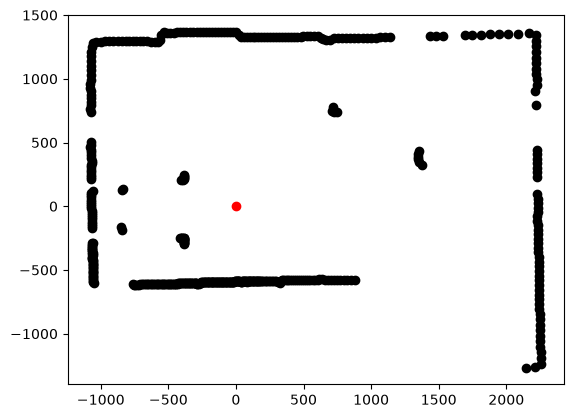

In [95]:
# send stop to flush any leftover scan data from previous session

lidar.set_motor_pwm(660)  # start motor
time.sleep(2)             # wait for motor to reach full speed

# start_scan() is the standard mode supported by all RPLIDAR models including C1
scan_generator = lidar.start_scan()

points = []
for i, scan in enumerate(scan_generator()):
    if scan.distance > 0:  # skip invalid points
        points.append((scan.angle, scan.distance))
    if i >= 500:
        break

lidar.stop()

print(f"Collected {len(points)} valid points")
print("\nFirst 10 points (angle°, distance mm):")
for angle, distance in points[:10]:
    print(f"  angle={angle:6.1f}°  dist={distance:7.1f} mm")

xy = [polar_to_xy(*p) for p in points]
xy = {"x": [p[0] for p in xy], "y": [p[1] for p in xy]}
plt.scatter(0, 0 , color= "red")
plt.scatter(xy["x"], xy["y"], color="black")
plt.show()

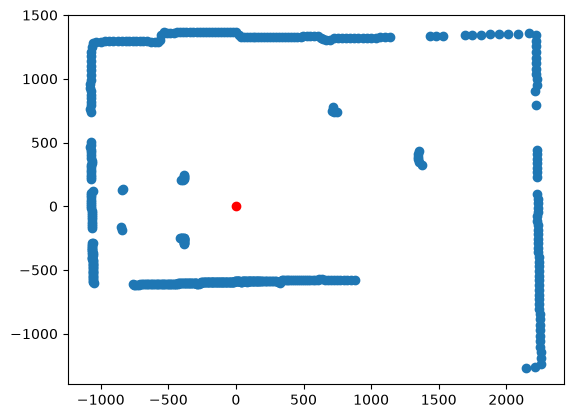

In [96]:
plt.scatter(0, 0 , color="red")
plt.scatter(xy["x"], xy["y"])
plt.show()

---
## Step 5 — Understand the data

| Field | Meaning |
|-------|---------|
| `angle` | Direction in degrees (0–360, clockwise from front) |
| `distance` | Distance to object in **millimetres** (0 = invalid) |

Let's look at basic statistics of the scan:

In [ ]:
distances = [d for _, d in points]

print(f"Total valid points : {len(points)}")
print(f"Min distance       : {min(distances):.0f} mm  ({min(distances)/1000:.2f} m)")
print(f"Max distance       : {max(distances):.0f} mm  ({max(distances)/1000:.2f} m)")
print(f"Avg distance       : {sum(distances)/len(distances):.0f} mm  ({sum(distances)/len(distances)/1000:.2f} m)")

---
## Step 6 — Visualise the scan (polar plot)

A polar plot shows exactly what the LiDAR "sees" around it.

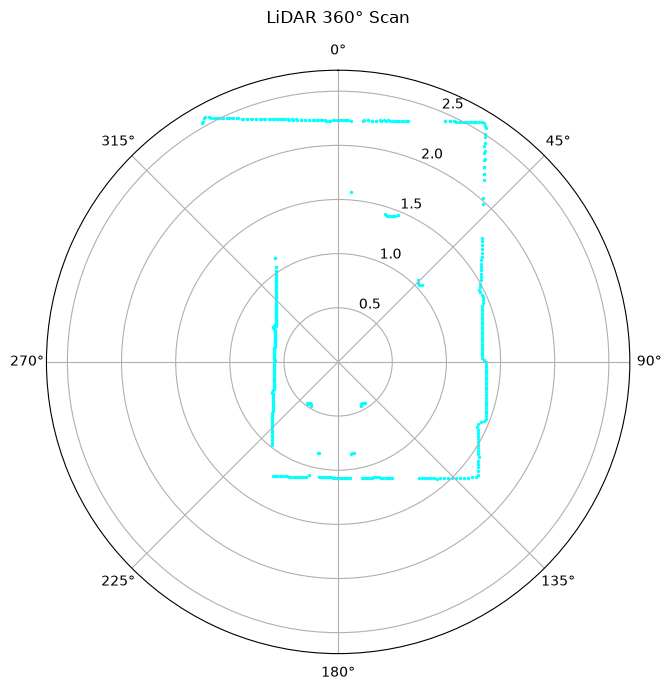

In [87]:
import math
import matplotlib.pyplot as plt

angles_rad  = [math.radians(a) for a, _ in points]
distances_m = [d / 1000        for _, d in points]  # mm → metres

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(7, 7))
ax.scatter(angles_rad, distances_m, s=2, c='cyan')
ax.set_title('LiDAR 360° Scan', pad=15)
ax.set_theta_zero_location('N')   # 0° at top
ax.set_theta_direction(-1)        # clockwise
plt.tight_layout()
plt.show()

---
## Step 7 — Live continuous scanning

Repeatedly captures scans and updates the plot in real time.  
Press the **Stop** button (■) in JupyterLab to interrupt.

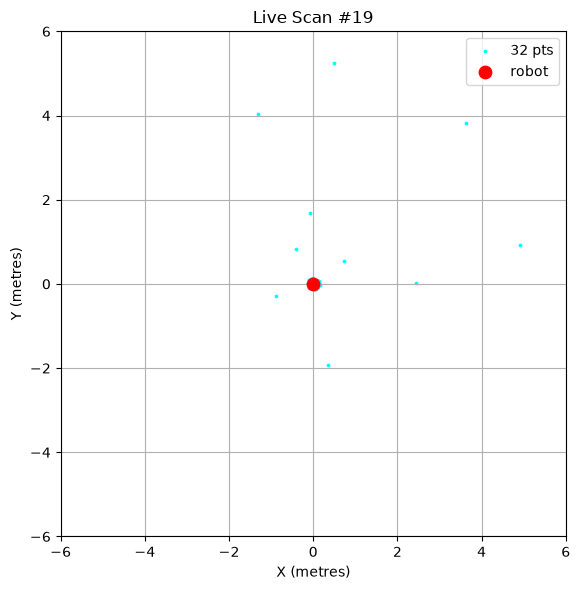

Stopped.


In [121]:
import math
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from pyrplidar import PyRPlidar
import time

PORT     = '/dev/ttyUSB0'
BAUDRATE = 460800  # C1 specific — do not change

# clean up any previous connection first
try:
    lidar.stop()
    lidar.set_motor_pwm(0)
    lidar.disconnect()
except:
    pass

lidar = PyRPlidar()
lidar.connect(port=PORT, baudrate=BAUDRATE, timeout=3)

# send stop to flush any leftover scan data from previous session
lidar.stop()
time.sleep(0.5)

print("Device info:", lidar.get_info())
print("Health:     ", lidar.get_health())

lidar.set_motor_pwm(660)
time.sleep(2)

scan_generator = lidar.start_scan()

RANGE_M    = 6   # max distance to show (metres)
POINT_SIZE = 3   # dot size

scan_num   = 0
points_buf = []
last_angle = None

try:
    for scan in scan_generator():
        if scan.distance > 0:
            angle = scan.angle

            # detect full revolution: angle resets from ~360 back to near 0
            if last_angle is not None and angle < 10 and last_angle > 350:
                if len(points_buf) > 300:   # enough points to be worth plotting
                    scan_num += 1

                    xs, ys = [], []
                    for a, d in points_buf:
                        d_m = d / 1000
                        if d_m <= RANGE_M:
                            xs.append(d_m * math.cos(math.radians(a)))
                            ys.append(d_m * math.sin(math.radians(a)))

                    fig, ax = plt.subplots(figsize=(6, 6))
                    ax.scatter(xs, ys, s=POINT_SIZE, c="cyan", label=f"{len(xs)} pts")
                    ax.scatter(0, 0, c="red", s=80, zorder=5, label="robot")
                    ax.set_xlim(-RANGE_M, RANGE_M)
                    ax.set_ylim(-RANGE_M, RANGE_M)
                    ax.set_xlabel("X (metres)")
                    ax.set_ylabel("Y (metres)")
                    ax.set_title(f"Live Scan #{scan_num}")
                    ax.set_aspect("equal")
                    ax.grid(True)
                    ax.legend(loc="upper right")
                    plt.tight_layout()

                    clear_output(wait=True)
                    display(fig)
                    plt.close(fig)

                    points_buf = []

            points_buf.append((angle, scan.distance))
            last_angle = angle

except KeyboardInterrupt:
    print("Stopped.")
finally:
    lidar.stop()

---
## Step 8 — Always disconnect when done

**Always run this cell when finished** — leaving the motor spinning wears it out.

In [ ]:
lidar.stop()
lidar.set_motor_pwm(0)
lidar.disconnect()
print("LiDAR disconnected safely.")

---
## Troubleshooting

| Problem | Fix |
|---------|-----|
| `Permission denied /dev/ttyUSB0` | `sudo usermod -aG dialout $USER` then re-login |
| `IndexError: index out of range` | Don't use `start_scan_express()` — C1 needs `start_scan()` |
| Device not found | Check USB cable; `ls /dev/ttyUSB*` in terminal |
| Scan freezes / no points | Re-run Step 3 to reconnect, then retry Step 4 |
| Motor doesn't spin | Try a powered USB hub (Pi may not supply enough current) |

In [1]:
!pwd


/home/priyanksharma/Desktop/lidarexp
